In [1]:
import pandas as pd
import numpy as np

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the distance between two points on Earth
    given their latitudes and longitudes in decimal degrees.
    """
    R = 6371  # Earth radius in kilometers
    
    lat1_rad = np.radians(lat1)
    lon1_rad = np.radians(lon1)
    lat2_rad = np.radians(lat2)
    lon2_rad = np.radians(lon2)
    
    dlon = lon2_rad - lon1_rad
    dlat = lat2_rad - lat1_rad
    
    a = np.sin(dlat / 2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    
    distance = R * c
    return distance

# --- Main Analysis ---
# Coimbatore International Airport (CJB) coordinates
airport_lat = 11.0300
airport_lon = 77.0435
search_radius_km = 1.0

# Use the full path to your CSV file
csv_path = "D:/Project_P1/data/ebird_observations.csv"

try:
    df = pd.read_csv(csv_path)

    # Ensure latitude and longitude are numeric, coercing errors
    df['LATITUDE'] = pd.to_numeric(df['LATITUDE'], errors='coerce')
    df['LONGITUDE'] = pd.to_numeric(df['LONGITUDE'], errors='coerce')

    # Drop rows with invalid coordinates
    df.dropna(subset=['LATITUDE', 'LONGITUDE'], inplace=True)

    # Calculate distance for each observation from the airport
    df['DISTANCE_TO_AIRPORT_KM'] = haversine_distance(
        airport_lat, airport_lon,
        df['LATITUDE'], df['LONGITUDE']
    )

    # Filter for observations within the 1 km radius
    nearby_birds = df[df['DISTANCE_TO_AIRPORT_KM'] <= search_radius_km].copy()

    print(f"--- Birds observed within {search_radius_km} km of Coimbatore Airport (CJB) ---")

    if nearby_birds.empty:
        print("No bird observations found within the specified radius in this dataset.")
    else:
        # Display a summary of the species found
        species_summary = nearby_birds['COMMON NAME'].value_counts()
        print(species_summary)
        
        # Display the full details for the nearby birds
        print("\n--- Detailed Observations ---")
        print(nearby_birds[['COMMON NAME', 'OBSERVATION COUNT', 'OBSERVATION DATE', 'DISTANCE_TO_AIRPORT_KM']])

except FileNotFoundError:
    print(f"Error: The file was not found at {csv_path}")
except Exception as e:
    print(f"An error occurred: {e}")

C:\Users\visha\AppData\Local\Temp\ipykernel_30916\4093030898.py:35: DtypeWarning: Columns (9,14,33,38) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


--- Birds observed within 1.0 km of Coimbatore Airport (CJB) ---
COMMON NAME
House Crow               111
Common Myna              108
Rock Pigeon              103
Yellow-billed Babbler     78
Indian Peafowl            75
                        ... 
Indian Thick-knee          1
white egret sp.            1
diurnal raptor sp.         1
passerine sp.              1
Plain Prinia               1
Name: count, Length: 88, dtype: int64

--- Detailed Observations ---
                       COMMON NAME OBSERVATION COUNT OBSERVATION DATE  \
746                   Barn Swallow                 X       1991-01-18   
757                     Black Kite                 X       1991-01-18   
792                     House Crow                 X       1991-01-18   
46972                   Asian Koel                 1       2014-11-01   
46975                   Asian Koel                 1       2014-11-01   
...                            ...               ...              ...   
1959206      Purple-rump

C:\Users\visha\AppData\Local\Temp\ipykernel_18668\2388184205.py:38: DtypeWarning: Columns (9,14,33,38) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


--- Dynamically Identified Threat Species (within 500m) ---
['Barn Swallow', 'Black Kite', 'Eurasian Kestrel', 'House Crow', 'Rose-ringed Parakeet', 'Red-wattled Lapwing', 'Asian Koel', 'Common Myna', 'Rock Pigeon', 'Yellow-wattled Lapwing', 'Indian Peafowl', 'Eastern Cattle-Egret', 'crow sp.', 'Indian Roller', 'Red-vented Bulbul', 'Black Drongo', 'Yellow-billed Babbler', 'white egret sp.', 'diurnal raptor sp.', 'bird sp.', 'Large-billed Crow', 'passerine sp.', 'Brahminy Kite', 'Indian Thick-knee', 'Pied Bushchat', 'Asian Palm Swift', 'Little Swift', 'Accipitrine hawk sp. (former Accipiter sp.)', 'Common Tailorbird', 'Coppersmith Barbet', 'Greater Coucal', 'Purple Sunbird', 'White-throated Kingfisher', 'Little Egret', 'Black-rumped Flameback', 'Rosy Starling']
----------------------------------------------------------



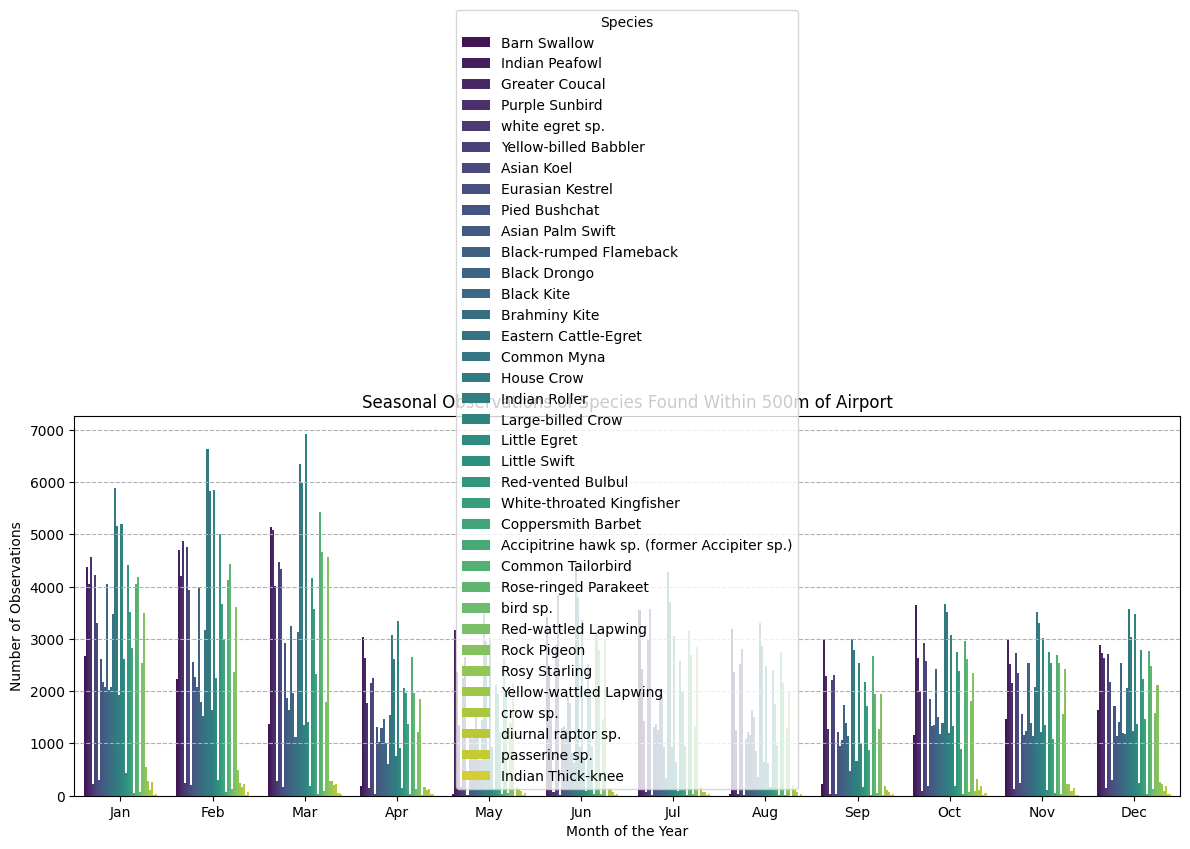

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the distance between two points on Earth
    given their latitudes and longitudes in decimal degrees.
    """
    R = 6371  # Earth radius in kilometers
    
    lat1_rad = np.radians(lat1)
    lon1_rad = np.radians(lon1)
    lat2_rad = np.radians(lat2)
    lon2_rad = np.radians(lon2)
    
    dlon = lon2_rad - lon1_rad
    dlat = lat2_rad - lat1_rad
    
    a = np.sin(dlat / 2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    
    distance = R * c
    return distance

# --- Main Analysis ---
# Coimbatore International Airport (CJB) coordinates
airport_lat = 11.0300
airport_lon = 77.0435
# Define the new, smaller radius for identifying threat species
nearby_radius_km = 0.5  # 100 meters

# Use the full path to your CSV file
csv_path = "D:/Project_P1/data/ebird_observations.csv"

try:
    df = pd.read_csv(csv_path)

    # --- Data Cleaning and Preparation ---
    df['LATITUDE'] = pd.to_numeric(df['LATITUDE'], errors='coerce')
    df['LONGITUDE'] = pd.to_numeric(df['LONGITUDE'], errors='coerce')
    df['OBSERVATION DATE'] = pd.to_datetime(df['OBSERVATION DATE'], errors='coerce')
    df.dropna(subset=['LATITUDE', 'LONGITUDE', 'OBSERVATION DATE'], inplace=True)

    # --- Dynamic Threat Species Identification ---
    # Calculate distance for all observations from the airport
    df['DISTANCE_TO_AIRPORT_KM'] = haversine_distance(
        airport_lat, airport_lon,
        df['LATITUDE'], df['LONGITUDE']
    )

    # Filter for birds within the 100m radius
    very_nearby_birds = df[df['DISTANCE_TO_AIRPORT_KM'] <= nearby_radius_km]

    # Dynamically create the list of threat species from this filtered data
    threat_species = very_nearby_birds['COMMON NAME'].unique().tolist()

    if not threat_species:
        print(f"Analysis Stopped: No bird species were found within {nearby_radius_km * 1000} meters of the airport in this dataset.")
    else:
        print(f"--- Dynamically Identified Threat Species (within 500m) ---")
        print(threat_species)
        print("----------------------------------------------------------\n")
        
        # --- Seasonal Analysis of Identified Species ---
        # Filter the *entire* dataframe for the dynamically identified species to see their broader seasonal patterns
        threat_df = df[df['COMMON NAME'].isin(threat_species)].copy()
        # threat_df = very_nearby_birds.copy()
        
        threat_df['MONTH'] = threat_df['OBSERVATION DATE'].dt.month
        
        # Create the count plot
        plt.figure(figsize=(12, 7))
        sns.countplot(x='MONTH', hue='COMMON NAME', data=threat_df, palette='viridis')
        
        plt.title(f'Seasonal Observations of Species Found Within {int(nearby_radius_km * 1000)}m of Airport')
        plt.xlabel('Month of the Year')
        plt.ylabel('Number of Observations')
        plt.xticks(ticks=range(12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
        plt.legend(title='Species')
        plt.grid(axis='y', linestyle='--')
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print(f"Error: The file was not found at {csv_path}")
except Exception as e:
    print(f"An error occurred: {e}")

C:\Users\visha\AppData\Local\Temp\ipykernel_30916\1881069312.py:46: DtypeWarning: Columns (9,14,33,38) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


--- Dynamically Identified Threat Species (within 250m) ---
['Barn Swallow', 'Black Kite', 'Eurasian Kestrel', 'House Crow', 'Rose-ringed Parakeet', 'Red-wattled Lapwing', 'Asian Koel', 'Common Myna', 'Rock Pigeon', 'Yellow-wattled Lapwing', 'Indian Peafowl', 'Eastern Cattle-Egret', 'crow sp.', 'Indian Roller', 'Red-vented Bulbul', 'Black Drongo', 'Yellow-billed Babbler', 'bird sp.', 'Accipitrine hawk sp. (former Accipiter sp.)']
----------------------------------------------------------



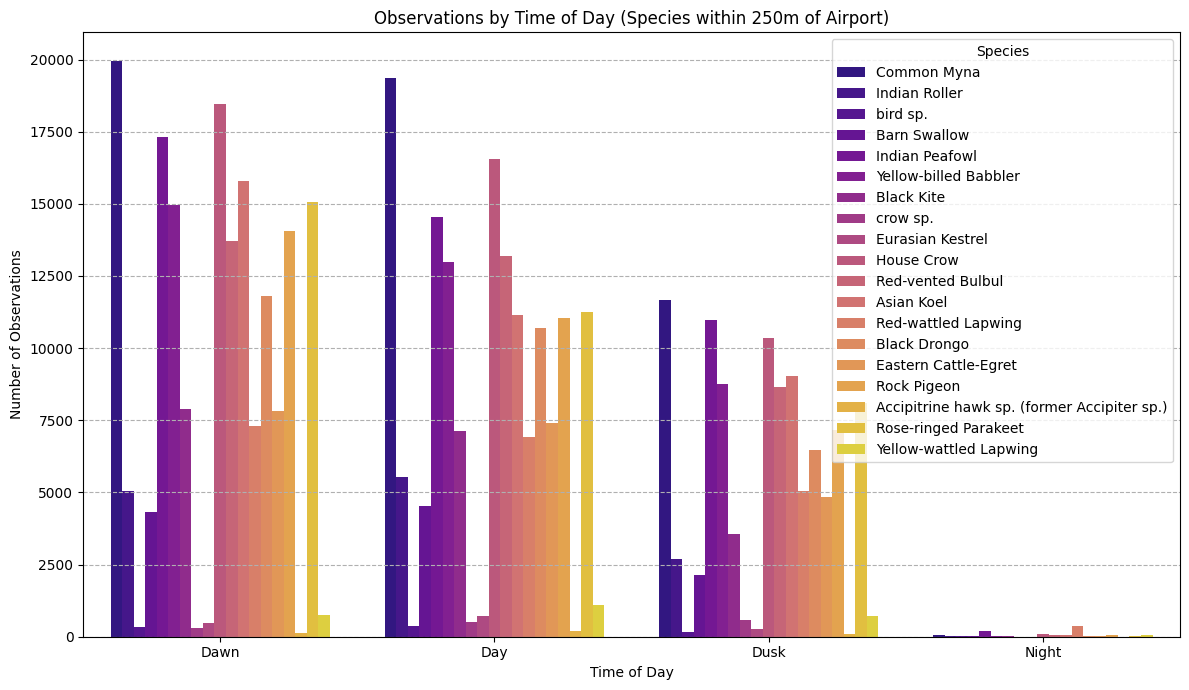

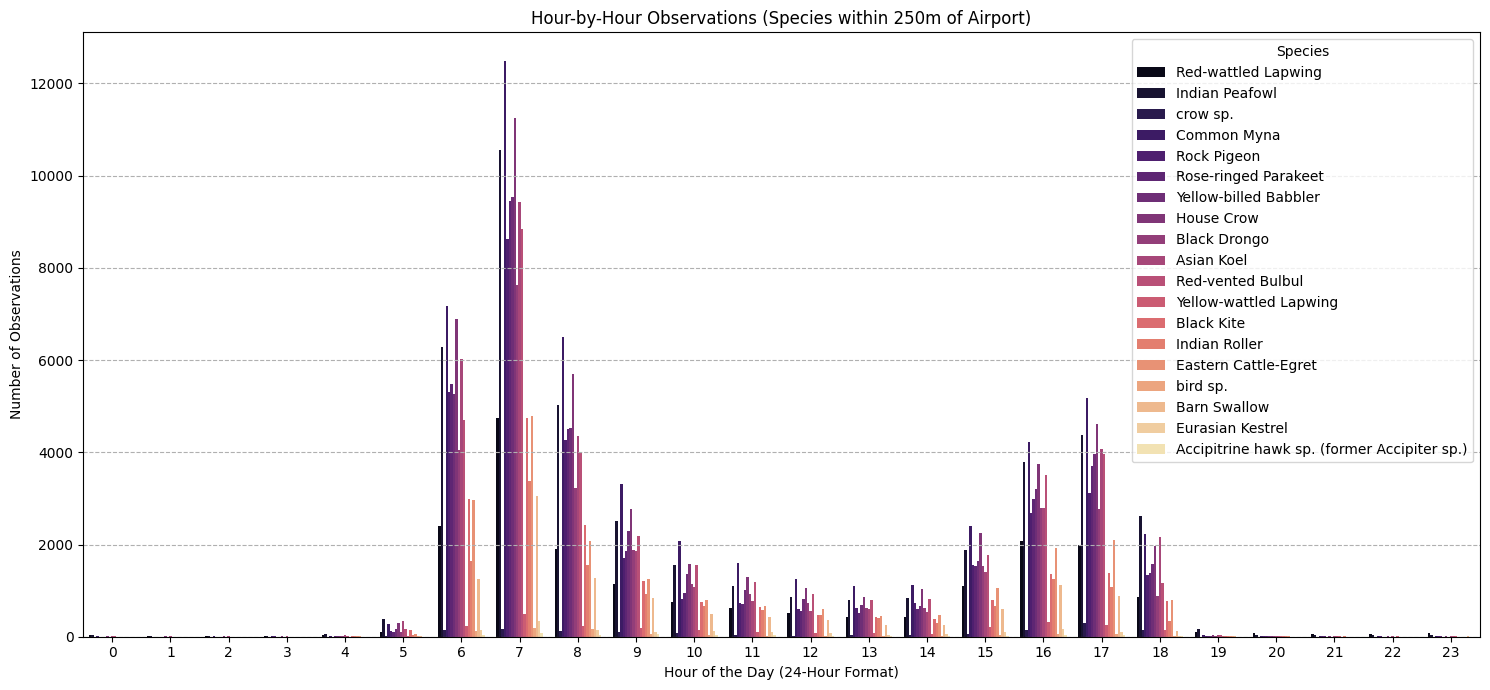

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the distance between two points on Earth
    given their latitudes and longitudes in decimal degrees.
    """
    R = 6371  # Earth radius in kilometers
    
    lat1_rad = np.radians(lat1)
    lon1_rad = np.radians(lon1)
    lat2_rad = np.radians(lat2)
    lon2_rad = np.radians(lon2)
    
    dlon = lon2_rad - lon1_rad
    dlat = lat2_rad - lat1_rad
    
    a = np.sin(dlat / 2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    
    distance = R * c
    return distance

def get_time_of_day(hour):
    """Categorizes the hour into a time of day."""
    if 4 <= hour < 8:
        return 'Dawn'
    elif 8 <= hour < 16:
        return 'Day'
    elif 16 <= hour < 20:
        return 'Dusk'
    else:
        return 'Night'

# --- Main Analysis ---
airport_lat = 11.0300
airport_lon = 77.0435
nearby_radius_km = 0.25  # 250 meters

csv_path = "D:/Project_P1/data/ebird_observations.csv"

try:
    df = pd.read_csv(csv_path)

    # --- Data Cleaning and Preparation ---
    df['LATITUDE'] = pd.to_numeric(df['LATITUDE'], errors='coerce')
    df['LONGITUDE'] = pd.to_numeric(df['LONGITUDE'], errors='coerce')
    df['OBSERVATION DATE'] = pd.to_datetime(df['OBSERVATION DATE'], errors='coerce')
    df.dropna(subset=['LATITUDE', 'LONGITUDE', 'OBSERVATION DATE'], inplace=True)

    # --- Dynamic Threat Species Identification ---
    df['DISTANCE_TO_AIRPORT_KM'] = haversine_distance(
        airport_lat, airport_lon,
        df['LATITUDE'], df['LONGITUDE']
    )
    very_nearby_birds = df[df['DISTANCE_TO_AIRPORT_KM'] <= nearby_radius_km]
    threat_species = very_nearby_birds['COMMON NAME'].unique().tolist()

    if not threat_species:
        print(f"Analysis Stopped: No bird species were found within {nearby_radius_km * 1000} meters of the airport in this dataset.")
    else:
        print(f"--- Dynamically Identified Threat Species (within 250m) ---")
        print(threat_species)
        print("----------------------------------------------------------\n")
        
        # --- Time-based Analysis of Identified Species ---
        threat_df = df[df['COMMON NAME'].isin(threat_species)].copy()
        
        # Parse the time column, coercing errors for missing values
        threat_df['TIME'] = pd.to_datetime(threat_df['TIME OBSERVATIONS STARTED'], format='%H:%M:%S', errors='coerce').dt.time
        threat_df.dropna(subset=['TIME'], inplace=True)
        
        # Extract hour and create time categories
        threat_df['HOUR'] = pd.to_datetime(threat_df['TIME'].astype(str), format='%H:%M:%S').dt.hour
        threat_df['TIME_OF_DAY'] = threat_df['HOUR'].apply(get_time_of_day)

        # --- PLOT 1: Time of Day Analysis ---
        plt.figure(figsize=(12, 7))
        sns.countplot(
            x='TIME_OF_DAY', 
            hue='COMMON NAME', 
            data=threat_df, 
            palette='plasma',
            order=['Dawn', 'Day', 'Dusk', 'Night']
        )
        plt.title(f'Observations by Time of Day (Species within {int(nearby_radius_km * 1000)}m of Airport)')
        plt.xlabel('Time of Day')
        plt.ylabel('Number of Observations')
        plt.legend(title='Species')
        plt.grid(axis='y', linestyle='--')
        plt.tight_layout()
        plt.show()

        # --- PLOT 2: Hour-by-Hour Analysis ---
        plt.figure(figsize=(15, 7))
        sns.countplot(x='HOUR', hue='COMMON NAME', data=threat_df, palette='magma')
        plt.title(f'Hour-by-Hour Observations (Species within {int(nearby_radius_km * 1000)}m of Airport)')
        plt.xlabel('Hour of the Day (24-Hour Format)')
        plt.ylabel('Number of Observations')
        plt.xticks(range(24))
        plt.legend(title='Species')
        plt.grid(axis='y', linestyle='--')
        plt.tight_layout()
        plt.show()

except FileNotFoundError:
    print(f"Error: The file was not found at {csv_path}")
except Exception as e:
    print(f"An error occurred: {e}")

### Review-03


Reading and cleaning data...
Data loaded successfully. Found 327023 records.

--- Generating Plot 1: Bird Strikes per Year ---


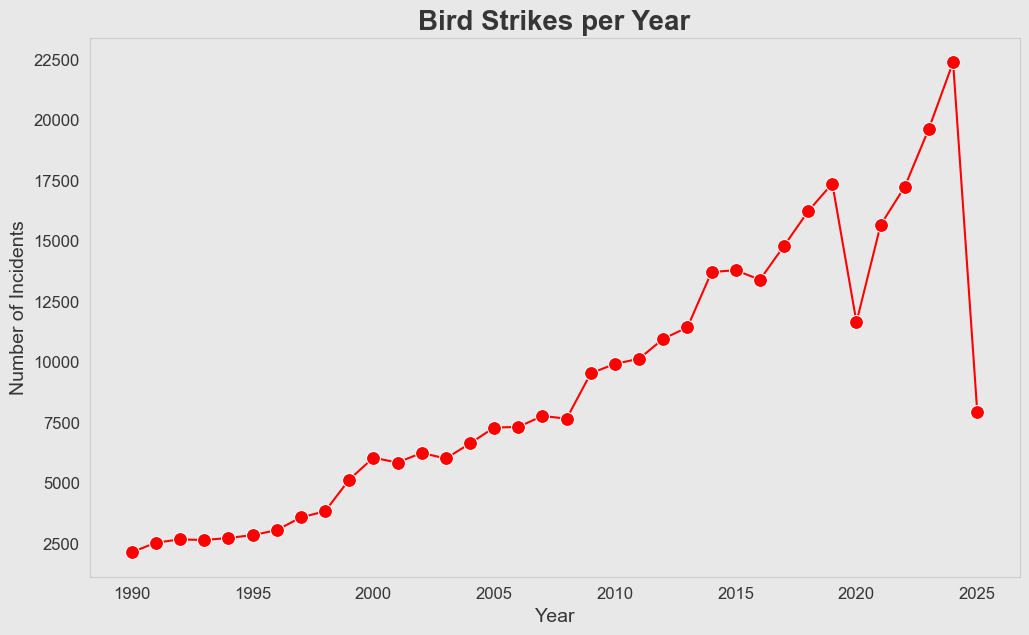


--- Generating Plot 2: Top 15 States with Bird Strikes ---


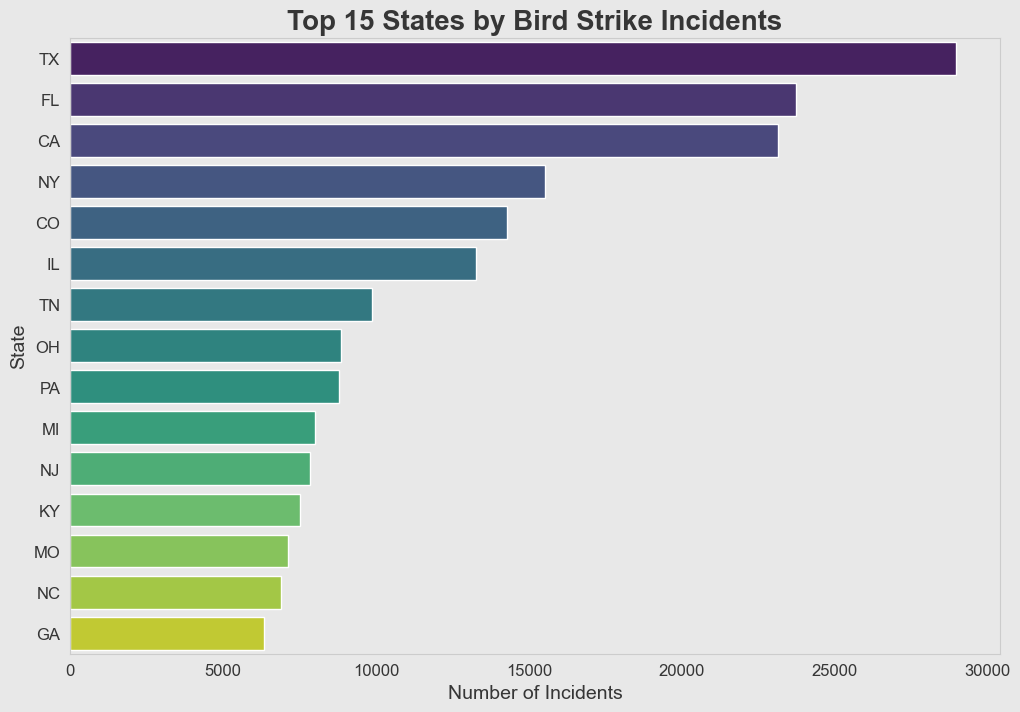


--- Generating Plot 3: Top 10 Airlines by Bird Strikes ---


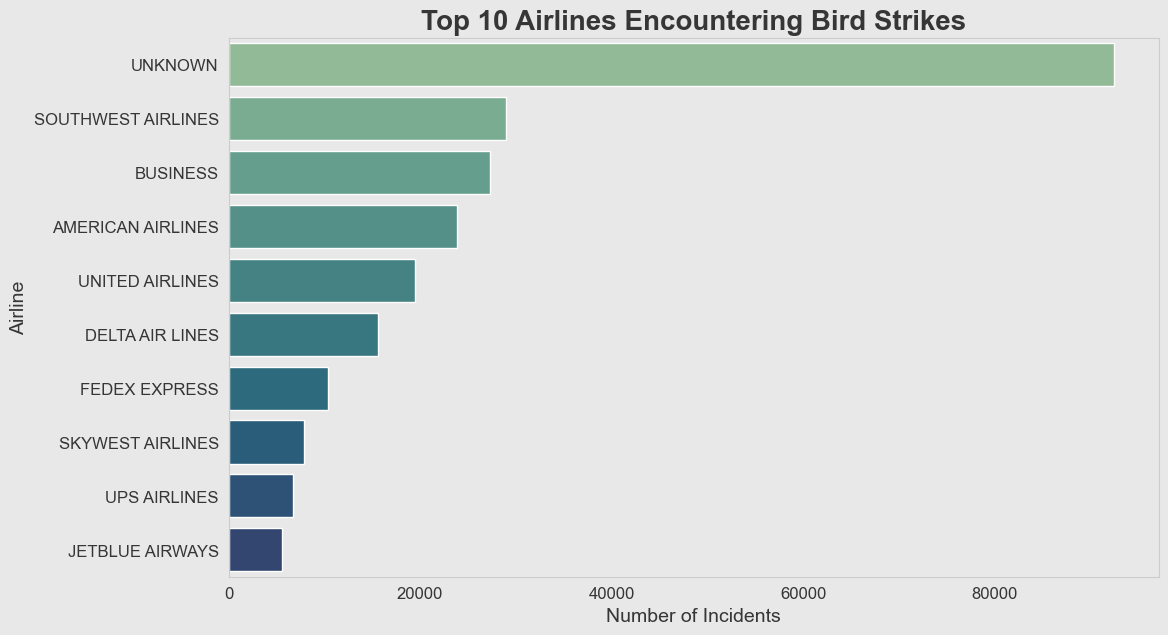


--- Generating Plot 4: Top 20 Airports by Bird Strikes ---


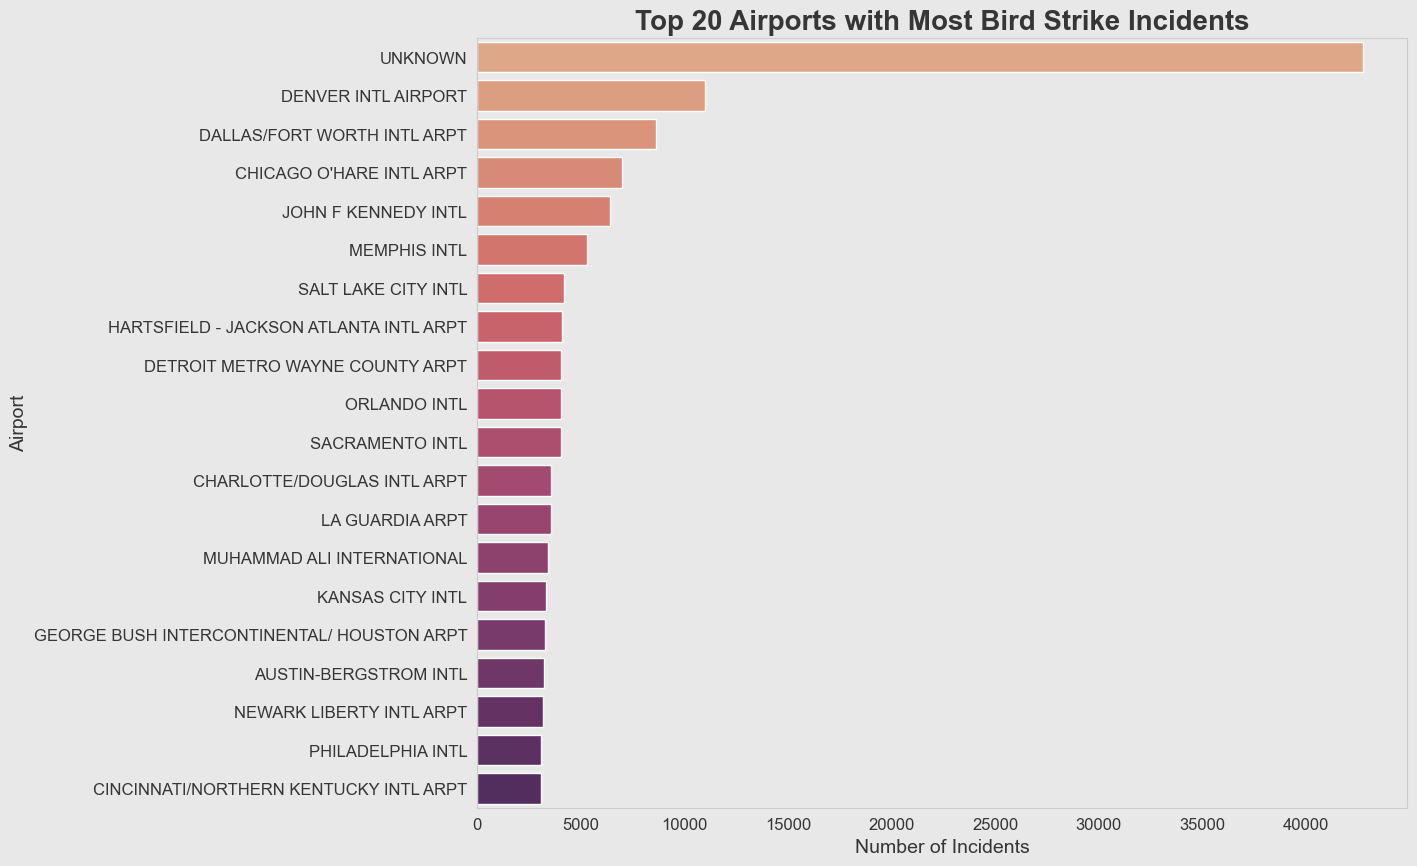


--- Generating Plot 5: Yearly Cost Incurred ---


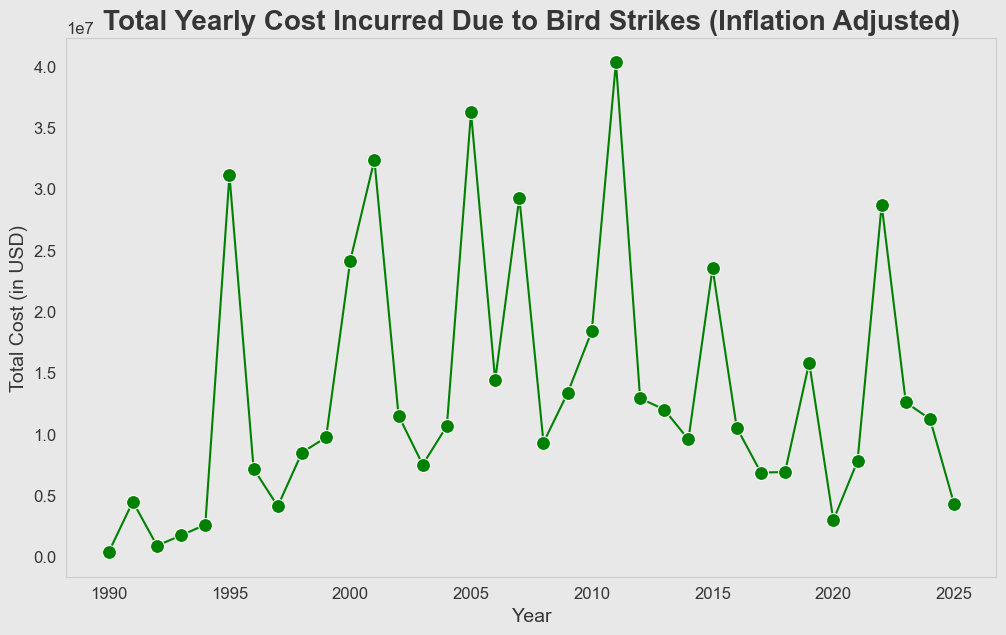


--- Generating Plot 6: Sky Condition by Year ---


C:\Users\visha\AppData\Local\Temp\ipykernel_18668\2114656208.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(data=sky_conditions_by_year, x='sky', y='counts', col='year', kind='bar',


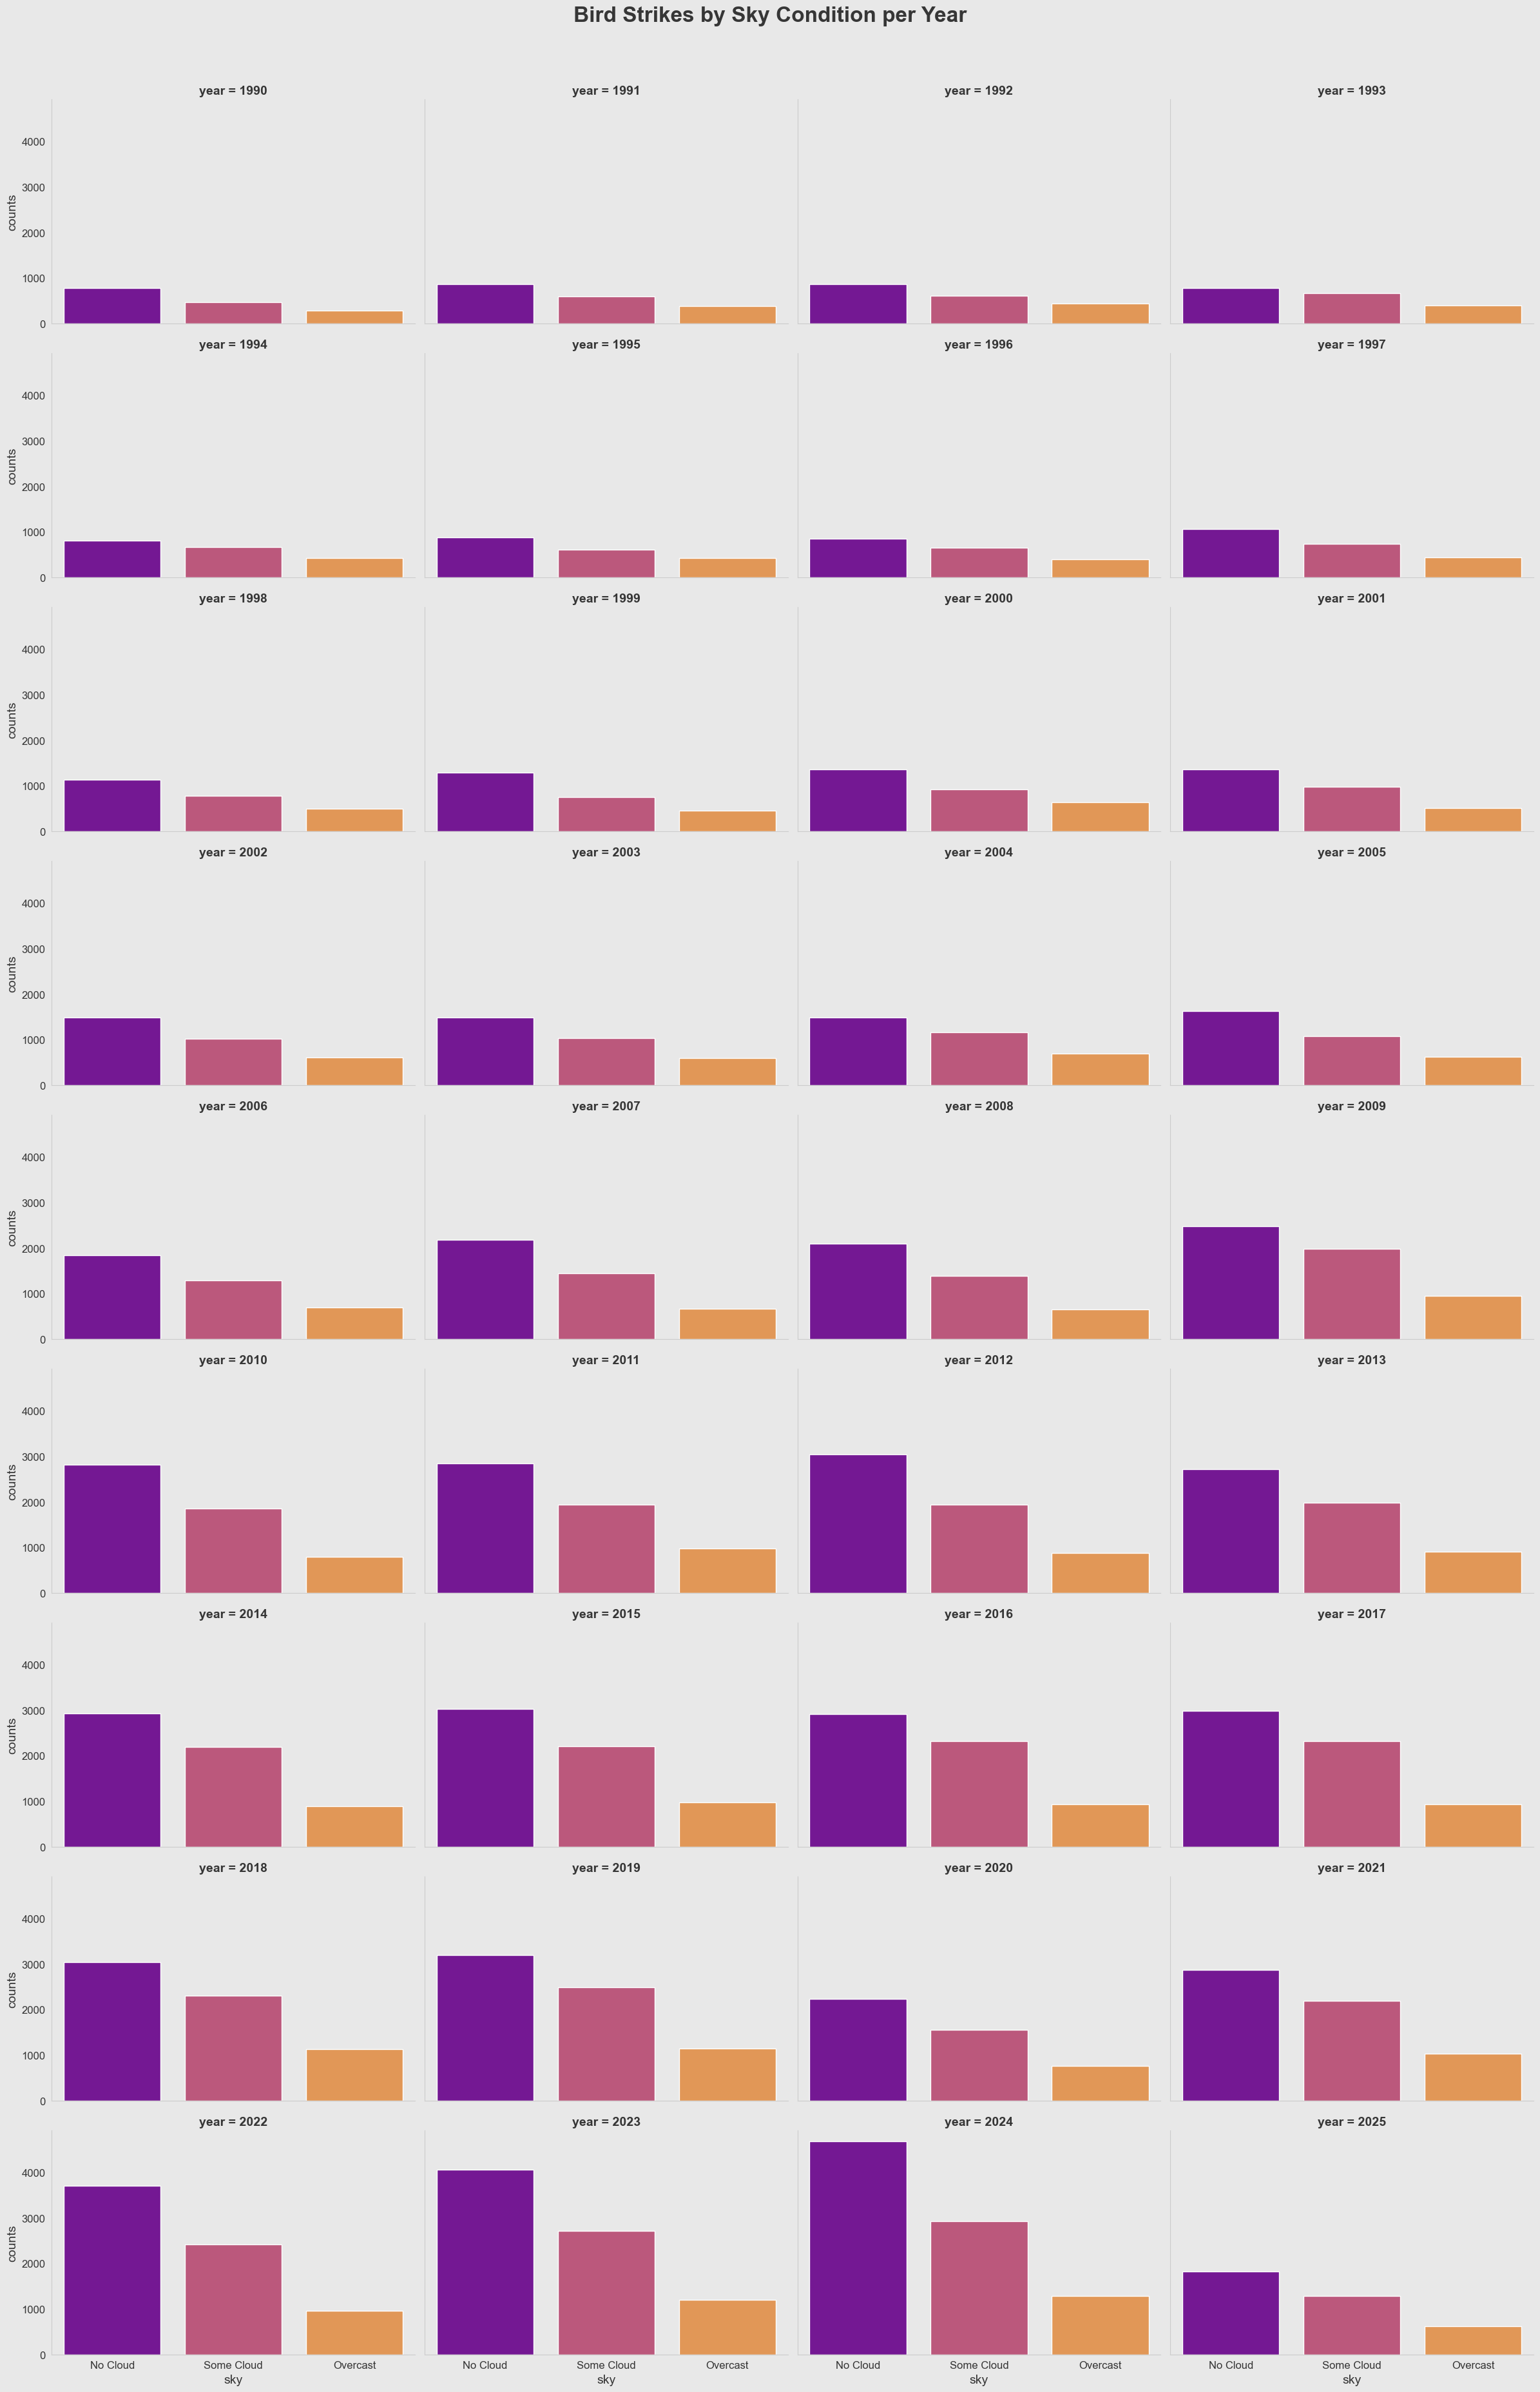


--- Generating Plot 7 & 8: Altitude Analysis ---


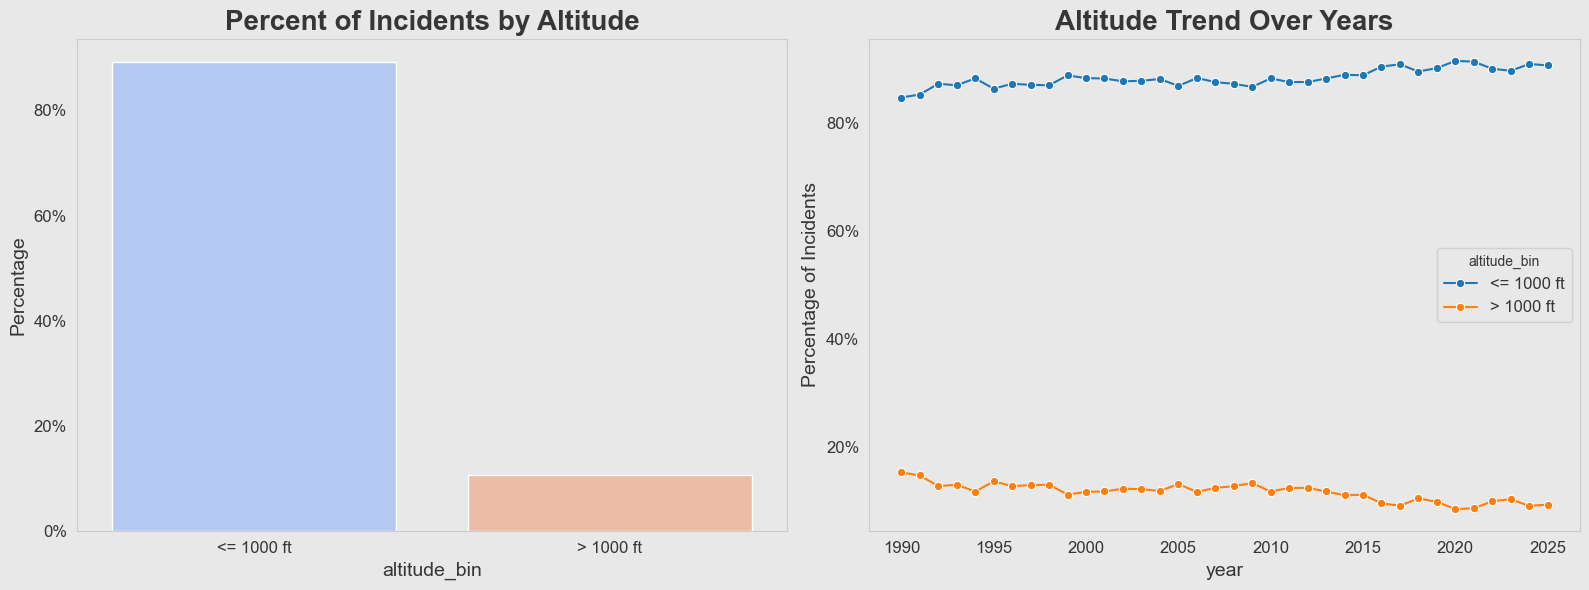


--- Generating Plot 9 & 10: Phase of Flight Analysis ---


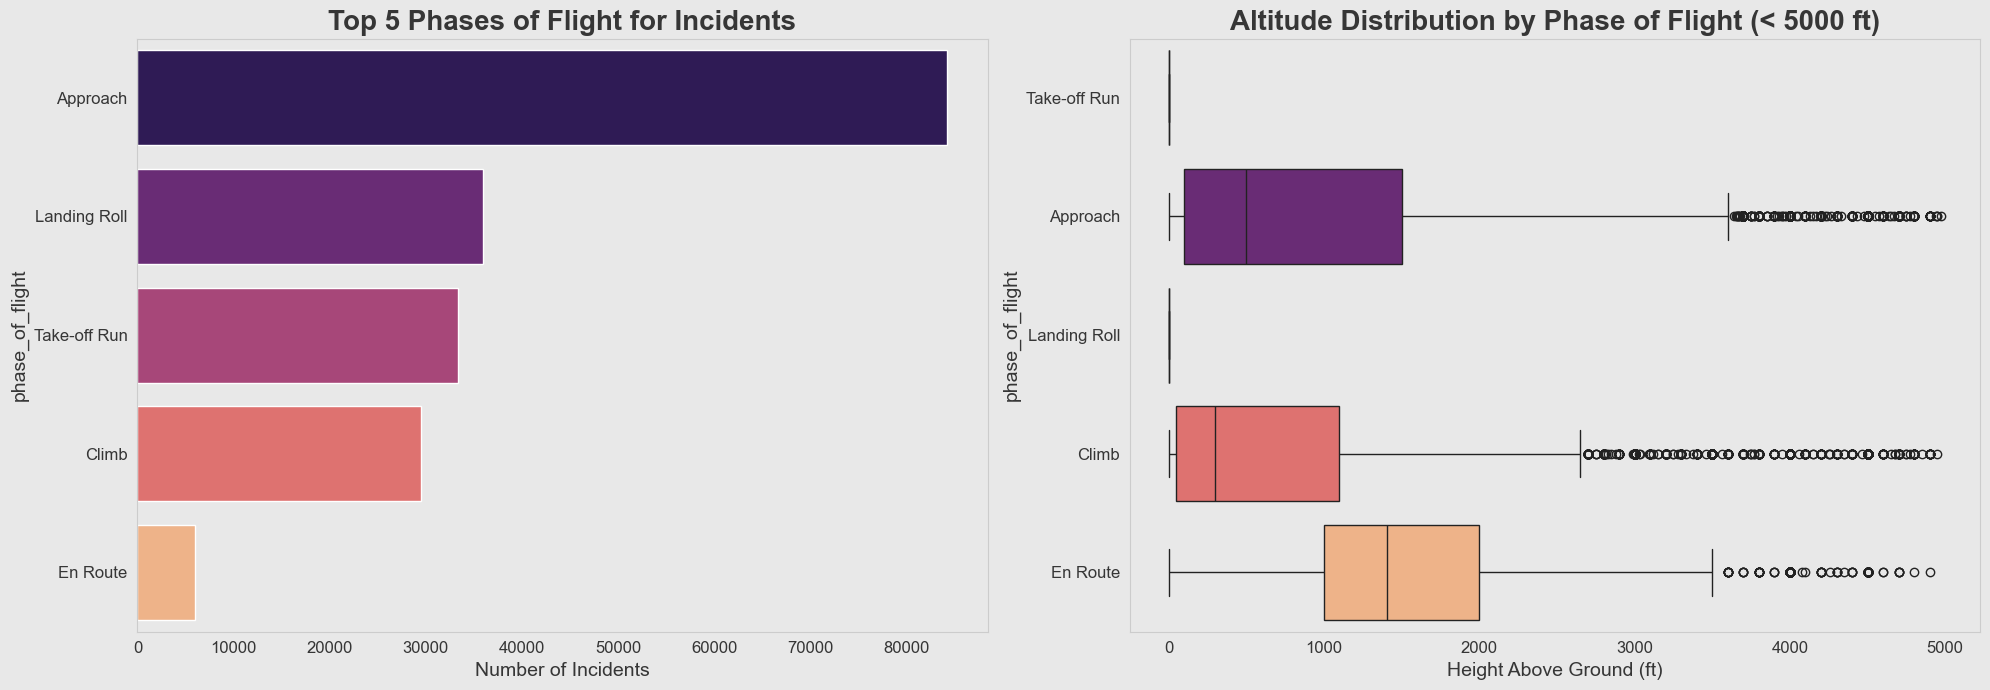


--- Generating Plot 11 & 12: Damage and Impact ---


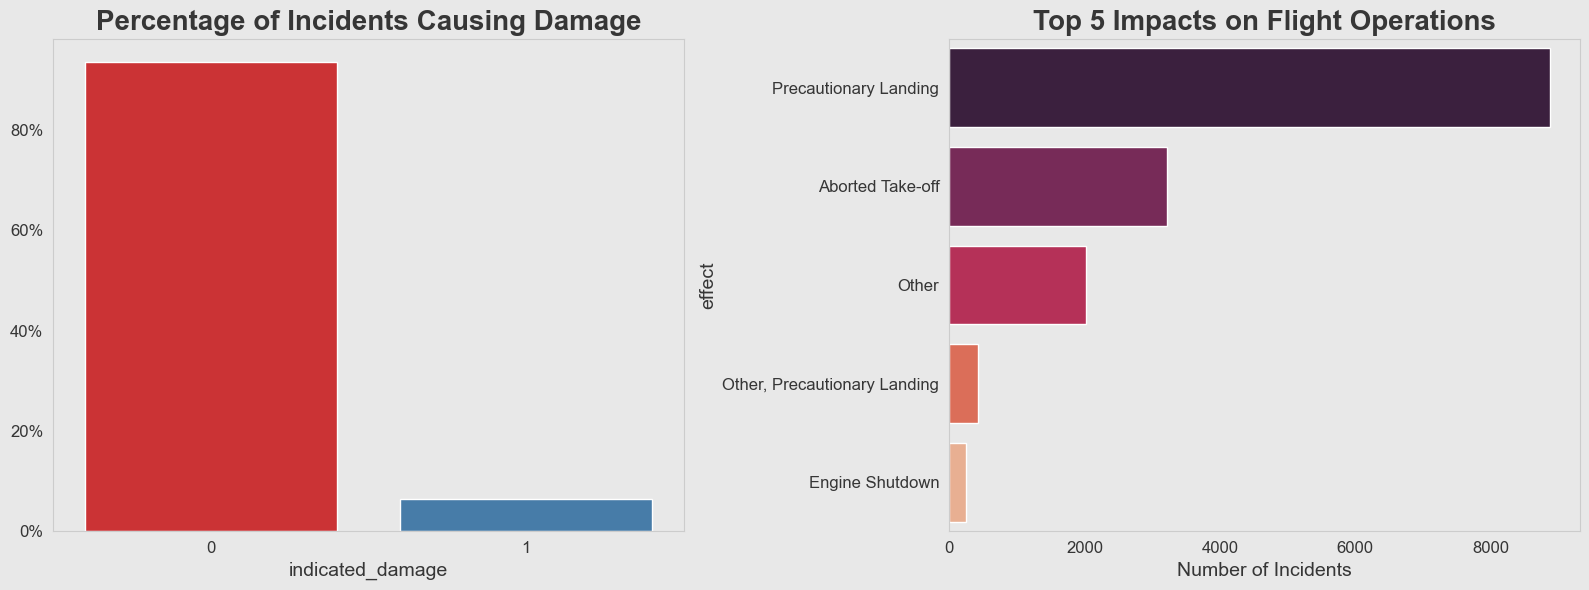


--- Generating Plot 13: Pilot Warning Analysis ---


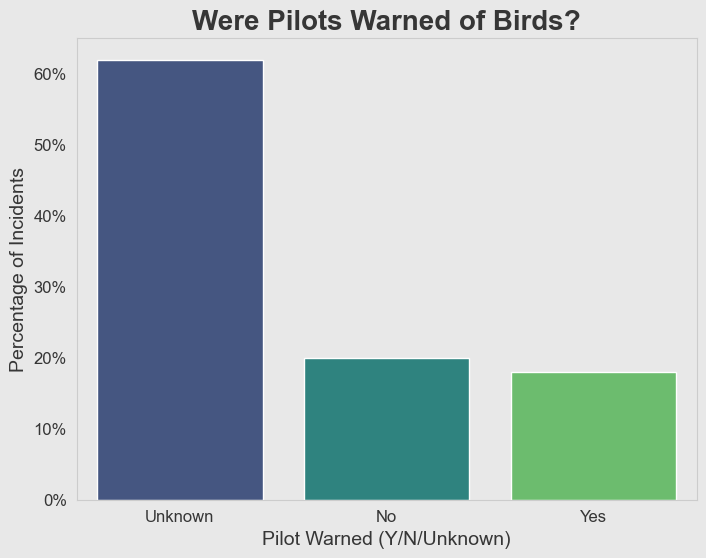


--- Generating Plot 14: Top 10 Species Involved ---


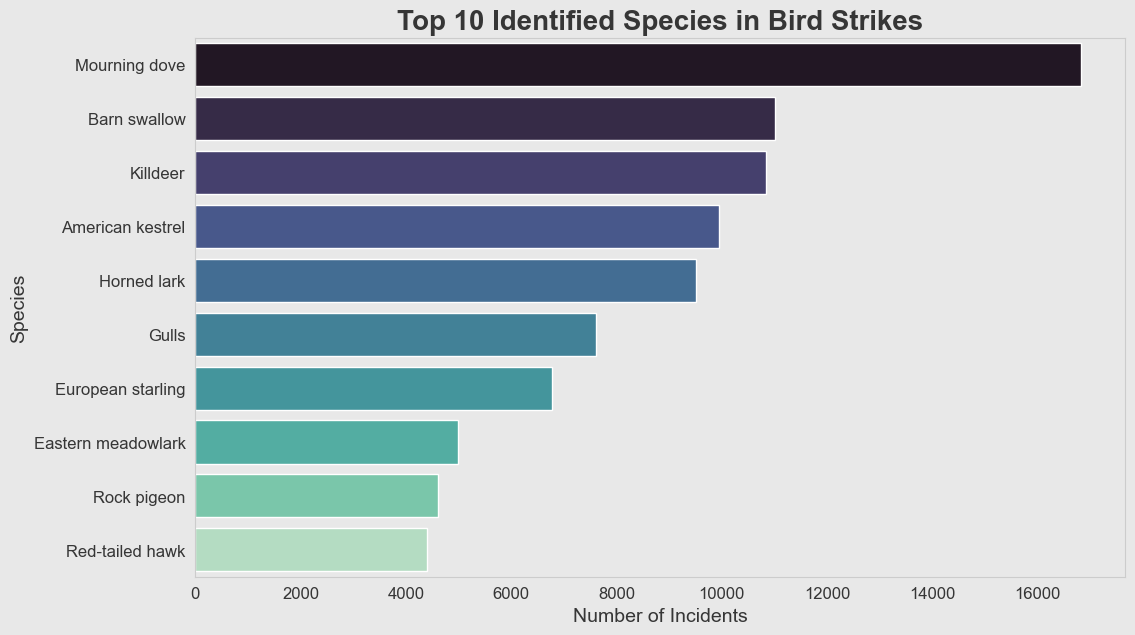

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def set_custom_theme():
    """Sets a clean, custom theme for all plots."""
    sns.set_style("whitegrid")
    plt.rcParams.update({
        'axes.facecolor': '#E8E8E8',
        'figure.facecolor': '#E8E8E8',
        'grid.color': '#E8E8E8',
        'text.color': '#363636',
        'axes.labelcolor': '#363636',
        'xtick.color': '#363636',
        'ytick.color': '#363636',
        'font.family': 'sans-serif',
        'axes.titlesize': 20,
        'axes.labelsize': 14,
        'xtick.labelsize': 12,
        'ytick.labelsize': 12,
        'legend.fontsize': 12,
        'figure.titlesize': 24,
        'figure.titleweight': 'bold',
        'axes.titleweight': 'bold'
    })

# Apply the custom theme
set_custom_theme()

# --- Main Analysis Script ---
try:
    # 1. READ AND CLEAN DATA
    print("Reading and cleaning data...")
    df = pd.read_excel('C:/Users/visha/Downloads/Public.xlsx')

    df.columns = df.columns.str.lower().str.replace(' ', '_')
    df['incident_date'] = pd.to_datetime(df['incident_date'], errors='coerce')
    df.dropna(subset=['incident_date'], inplace=True)
    df['year'] = df['incident_date'].dt.year
    df['month'] = df['incident_date'].dt.month
    print(f"Data loaded successfully. Found {len(df)} records.")

    # --- Start of Plotting ---

    # Plot 1: Bird Strikes per Year
    print("\n--- Generating Plot 1: Bird Strikes per Year ---")
    yearly_strikes = df['year'].value_counts().sort_index()
    plt.figure(figsize=(12, 7))
    sns.lineplot(x=yearly_strikes.index, y=yearly_strikes.values, marker='o', markersize=10, color='red')
    plt.title('Bird Strikes per Year')
    plt.xlabel('Year')
    plt.ylabel('Number of Incidents')
    plt.grid(False)
    plt.show()

    # Plot 2: Top 15 States with Bird Strikes
    print("\n--- Generating Plot 2: Top 15 States with Bird Strikes ---")
    plt.figure(figsize=(12, 8))
    state_strikes = df['state'].value_counts().nlargest(15)
    sns.barplot(x=state_strikes.values, y=state_strikes.index, hue=state_strikes.index, palette='viridis', legend=False)
    plt.title('Top 15 States by Bird Strike Incidents')
    plt.xlabel('Number of Incidents')
    plt.ylabel('State')
    plt.grid(False)
    plt.show()

    # Plot 3: Top 10 Airlines
    print("\n--- Generating Plot 3: Top 10 Airlines by Bird Strikes ---")
    plt.figure(figsize=(12, 7))
    airline_strikes = df['operator'].value_counts().nlargest(10)
    sns.barplot(x=airline_strikes.values, y=airline_strikes.index, hue=airline_strikes.index, palette='crest', legend=False)
    plt.title('Top 10 Airlines Encountering Bird Strikes')
    plt.xlabel('Number of Incidents')
    plt.ylabel('Airline')
    plt.grid(False)
    plt.show()

    # Plot 4: Top 20 Airports
    print("\n--- Generating Plot 4: Top 20 Airports by Bird Strikes ---")
    plt.figure(figsize=(12, 10))
    airport_strikes = df['airport'].value_counts().nlargest(20)
    sns.barplot(x=airport_strikes.values, y=airport_strikes.index, hue=airport_strikes.index, palette='flare', legend=False)
    plt.title('Top 20 Airports with Most Bird Strike Incidents')
    plt.xlabel('Number of Incidents')
    plt.ylabel('Airport')
    plt.grid(False)
    plt.show()
    
    # Plot 5: Yearly Cost
    print("\n--- Generating Plot 5: Yearly Cost Incurred ---")
    df['cost_total'] = df['cost_repairs_infl_adj'] + df['cost_other_infl_adj']
    yearly_cost = df.groupby('year')['cost_total'].sum()
    plt.figure(figsize=(12, 7))
    sns.lineplot(x=yearly_cost.index, y=yearly_cost.values, marker='o', markersize=10, color='green')
    plt.title('Total Yearly Cost Incurred Due to Bird Strikes (Inflation Adjusted)')
    plt.xlabel('Year')
    plt.ylabel('Total Cost (in USD)')
    plt.grid(False)
    plt.show()

    # Plot 6: Sky Condition by Year
    print("\n--- Generating Plot 6: Sky Condition by Year ---")
    sky_conditions_by_year = df.groupby('year')['sky'].value_counts().rename('counts').reset_index()
    sns.catplot(data=sky_conditions_by_year, x='sky', y='counts', col='year', kind='bar', 
                col_wrap=4, palette='plasma', height=4, aspect=1.5)
    plt.suptitle('Bird Strikes by Sky Condition per Year', y=1.03)
    plt.show()
    
    # Plot 7 & 8: Altitude Analysis
    print("\n--- Generating Plot 7 & 8: Altitude Analysis ---")
    df['altitude_bin'] = np.where(df['height'] > 1000, '> 1000 ft', '<= 1000 ft')
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    # Overall
    altitude_counts = df['altitude_bin'].value_counts(normalize=True)
    sns.barplot(ax=axes[0], x=altitude_counts.index, y=altitude_counts.values, hue=altitude_counts.index, palette='coolwarm', legend=False)
    axes[0].set_title('Percent of Incidents by Altitude')
    axes[0].set_ylabel('Percentage')
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))
    # By Year
    altitude_by_year = df.groupby('year')['altitude_bin'].value_counts(normalize=True).rename('percentage').reset_index()
    sns.lineplot(ax=axes[1], data=altitude_by_year, x='year', y='percentage', hue='altitude_bin', marker='o')
    axes[1].set_title('Altitude Trend Over Years')
    axes[1].set_ylabel('Percentage of Incidents')
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))
    plt.tight_layout()
    plt.show()

    # Plot 9 & 10: Phase of Flight and Altitude
    print("\n--- Generating Plot 9 & 10: Phase of Flight Analysis ---")
    fig, axes = plt.subplots(1, 2, figsize=(20, 7))
    # Bar Plot
    flight_phase_counts = df['phase_of_flight'].value_counts().nlargest(5)
    sns.barplot(ax=axes[0], x=flight_phase_counts.values, y=flight_phase_counts.index, hue=flight_phase_counts.index, palette='magma', legend=False)
    axes[0].set_title('Top 5 Phases of Flight for Incidents')
    axes[0].set_xlabel('Number of Incidents')
    # Box Plot
    top_phases = flight_phase_counts.index
    df_filtered_height = df[df['phase_of_flight'].isin(top_phases) & (df['height'] < 5000)] # Filter outliers
    sns.boxplot(ax=axes[1], data=df_filtered_height, y='phase_of_flight', x='height', hue='phase_of_flight', palette='magma', legend=False)
    axes[1].set_title('Altitude Distribution by Phase of Flight (< 5000 ft)')
    axes[1].set_xlabel('Height Above Ground (ft)')
    plt.tight_layout()
    plt.show()

    # Plot 11 & 12: Damage and Impact on Flight
    print("\n--- Generating Plot 11 & 12: Damage and Impact ---")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    # Damage
    damage_counts = df['indicated_damage'].value_counts(normalize=True)
    sns.barplot(ax=axes[0], x=damage_counts.index, y=damage_counts.values, hue=damage_counts.index, palette='Set1', legend=False)
    axes[0].set_title('Percentage of Incidents Causing Damage')
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))
    # Impact
    impact_counts = df[df['effect'] != 'None']['effect'].value_counts().nlargest(5)
    sns.barplot(ax=axes[1], x=impact_counts.values, y=impact_counts.index, hue=impact_counts.index, palette='rocket', legend=False)
    axes[1].set_title('Top 5 Impacts on Flight Operations')
    axes[1].set_xlabel('Number of Incidents')
    plt.tight_layout()
    plt.show()
    
    # Plot 13: Pilot Warned
    print("\n--- Generating Plot 13: Pilot Warning Analysis ---")
    warned_counts = df['warned'].value_counts(normalize=True)
    plt.figure(figsize=(8, 6))
    sns.barplot(x=warned_counts.index, y=warned_counts.values, hue=warned_counts.index, palette='viridis', legend=False)
    plt.title('Were Pilots Warned of Birds?')
    plt.xlabel('Pilot Warned (Y/N/Unknown)')
    plt.ylabel('Percentage of Incidents')
    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))
    plt.show()

    # Plot 14: Top 10 Wildlife Species
    print("\n--- Generating Plot 14: Top 10 Species Involved ---")
    plt.figure(figsize=(12, 7))
    species_counts = df[~df['species'].str.contains("Unknown", na=False)]['species'].value_counts().nlargest(10)
    sns.barplot(x=species_counts.values, y=species_counts.index, hue=species_counts.index, palette='mako', legend=False)
    plt.title('Top 10 Identified Species in Bird Strikes')
    plt.xlabel('Number of Incidents')
    plt.ylabel('Species')
    plt.grid(False)
    plt.show()

except FileNotFoundError:
    print("Error: 'faa_wildlife_strikes.csv' not found.")
    print("Please make sure you have saved the dataset file in the same directory as this script.")
except Exception as e:
    print(f"An error occurred: {e}")